# 04 · Pembuktian Batasan MLP Classifier untuk Image Generation
**Deep Learning (D6421) – Sesi 07: Generative Models | Tugas Take-Home**

Tahap 1 (latih MLP Classifier `784→256→64→10`), Tahap 2–3 (proyeksi transpos bobot), Tahap 4 (frozen latent decoder vs Vanilla AE), Tahap 5 (prior sampling), ditambah bukti numerik $W^\top W \neq I$ dan rasio variansi intra-kelas. Menghasilkan Figur 3. Bahan untuk Q5.

Vanilla AE dipakai sebagai pembanding; kalau `01_autoencoders.ipynb` sudah dijalankan, checkpoint-nya dimuat dari Drive.

**Sebelum run (Colab):** *Runtime → Change runtime type → T4 GPU*. Notebook akan meminta izin mount Google Drive; semua checkpoint, tabel, dan figur disimpan ke folder `GSLC2/final_results/` di Drive.

Notebook ini **mandiri**: model yang dibutuhkan tapi belum ada di Drive akan dilatih di sini. Kalau sudah dilatih notebook lain (folder output yang sama), checkpoint-nya langsung dimuat.

## 1. Setup

In [7]:
!pip install -q torch-fidelity torchmetrics

In [8]:
import os
os.environ.setdefault("PYTORCH_CUDA_ALLOC_CONF", "expandable_segments:True")

import copy
import csv
import glob
import json
import math
import random
import shutil
import statistics
import time
from dataclasses import asdict, dataclass
from typing import Tuple

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from IPython.display import Image, Markdown, display
from matplotlib.gridspec import GridSpec
from torch.utils.data import DataLoader, TensorDataset

print("torch", torch.__version__, "| CUDA:", torch.cuda.is_available(),
      "|", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU")

torch 2.14.1+cu130 | CUDA: True | Tesla T4


### Konfigurasi
Semua hyperparameter ada di sini, jadi bisa langsung dipindah ke **Tabel Konfigurasi** (Bagian II laporan). Nilainya identik di kelima notebook.

In [9]:
@dataclass
class Config:
    # ---- Umum ----
    seed: int = 42
    data_root: str = "./data"
    out_dir: str = "./outputs"
    batch_size: int = 128
    num_workers: int = 0              # data di-preload ke tensor -> 0 sudah cepat
    fake_data: bool = False           # True = smoke test dengan data sintetis
    deterministic: bool = False
    train_frac: float = 0.8
    val_frac: float = 0.1

    # ---- Keluarga Autoencoder (backbone sama: 784-256-64-256-784) ----
    img_dim: int = 784
    hidden_dim: int = 256
    latent_dim: int = 64
    ae_epochs: int = 30
    ae_lr: float = 1e-3
    sparse_lambda: float = 1e-4       # lambda * ||h||_1
    sparse_sweep: Tuple[float, ...] = (0.0, 1e-5, 1e-4, 1e-3)
    sweep_epochs: int = 20
    vae_recon_loss: str = "bce"       # "bce" | "mse" (dijumlah per citra)
    vae_beta: float = 1.0

    # ---- GAN ----
    z_dim: int = 100
    gan_epochs: int = 60
    dcgan_epochs: int = 30
    gan_lr: float = 2e-4
    gan_beta1: float = 0.5
    gan_loss: str = "nonsat"          # "nonsat" | "minimax"
    dcgan_ngf: int = 64
    dcgan_ndf: int = 64
    gan_log_every: int = 10

    # ---- DDPM ----
    ddpm_epochs: int = 40
    ddpm_lr: float = 2e-4
    ddpm_T: int = 1000
    ddpm_beta_start: float = 1e-4
    ddpm_beta_end: float = 0.02
    ddpm_base_ch: int = 64
    ddpm_ch_mults: Tuple[int, ...] = (1, 2, 2)
    ddpm_num_res_blocks: int = 2
    ddpm_attn_res: Tuple[int, ...] = (7,)
    ddpm_dropout: float = 0.1
    ddpm_ema_decay: float = 0.999
    ddpm_amp: bool = True
    ddpm_sample_batch: int = 500
    ddpm_val_batches: int = 20

    # ---- MLP Classifier (Bagian 2): 784 -> 256 -> 64 -> 10 ----
    clf_epochs: int = 25
    clf_lr: float = 1e-3
    clf_dropout: float = 0.2
    clf_min_acc: float = 0.88
    latent_dec_epochs: int = 30       # = ae_epochs agar adil vs Vanilla AE

    # ---- Evaluasi ----
    fid_feature: int = 2048
    fid_n_samples: int = 0            # 0 = samakan dengan ukuran test set
    fid_batch: int = 100              # Inception resize ke 299x299 -> batch besar = OOM di T4
    latency_batch: int = 64
    latency_runs: int = 20
    latency_runs_ddpm: int = 3
    interp_classes: Tuple[int, int] = (1, 8)      # Trouser vs Bag
    interp_alphas: Tuple[float, ...] = (0.0, 0.2, 0.4, 0.6, 0.8, 1.0)
    gan_interp_candidates: int = 2000

    def apply_fake_data_overrides(self):
        """Mode smoke test: semuanya kecil agar pipeline bisa dicek cepat di CPU."""
        self.ae_epochs = self.sweep_epochs = self.clf_epochs = self.latent_dec_epochs = 1
        self.gan_epochs = self.dcgan_epochs = self.ddpm_epochs = 1
        self.ddpm_T = 20
        self.ddpm_base_ch = 32
        self.ddpm_num_res_blocks = 1
        self.ddpm_sample_batch = 64
        self.ddpm_val_batches = 2
        self.fid_n_samples = 128
        self.latency_runs = 2
        self.latency_runs_ddpm = 1
        self.sparse_sweep = (0.0, 1e-4)
        self.clf_min_acc = 0.0
        self.gan_interp_candidates = 200


CLASS_NAMES = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
               "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]


GENERATIVE = ["vanilla_ae", "sparse_ae", "vae", "vanilla_gan", "dcgan", "ddpm"]


PRETTY = {"vanilla_ae": "Vanilla AE", "sparse_ae": "Sparse AE", "vae": "VAE",
          "vanilla_gan": "Vanilla GAN", "dcgan": "DCGAN", "ddpm": "DDPM",
          "mlp_classifier": "MLP Classifier", "latent_decoder": "Frozen-Latent Decoder"}

### Utilitas

In [10]:
def set_seed(seed=42, deterministic=False):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    if deterministic:
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False


def get_device():
    return torch.device("cuda" if torch.cuda.is_available() else "cpu")


def ensure_dir(path):
    os.makedirs(path, exist_ok=True)
    return path


def _json_default(o):
    if isinstance(o, (np.floating, np.integer)):
        return o.item()
    if isinstance(o, torch.Tensor):
        return o.detach().cpu().tolist()
    if isinstance(o, tuple):
        return list(o)
    raise TypeError(f"Tidak bisa serialisasi {type(o)}")


def save_json(obj, path):
    ensure_dir(os.path.dirname(path) or ".")
    with open(path, "w") as f:
        json.dump(obj, f, indent=2, default=_json_default)


def to_01(x):
    """[-1, 1] -> [0, 1]"""
    return ((x + 1) / 2).clamp(0, 1)


def to_pm1(x):
    """[0, 1] -> [-1, 1]"""
    return x * 2 - 1


def count_params(model):
    return sum(p.numel() for p in model.parameters())


def _sync(device):
    if device.type == "cuda":
        torch.cuda.synchronize()


@torch.no_grad()
def measure_latency(fn, device, n_warmup=3, n_runs=20):
    """Median & std latensi (ms) satu pemanggilan fn(). synchronize agar waktu GPU terhitung."""
    for _ in range(n_warmup):
        fn()
    _sync(device)
    times = []
    for _ in range(n_runs):
        _sync(device)
        t0 = time.perf_counter()
        fn()
        _sync(device)
        times.append((time.perf_counter() - t0) * 1000.0)
    return {"median_ms": statistics.median(times),
            "std_ms": statistics.pstdev(times) if len(times) > 1 else 0.0,
            "n_runs": n_runs}


def _free_cuda():
    import gc
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()


def log(msg):
    print(f"[{time.strftime('%H:%M:%S')}] {msg}", flush=True)

### Data
torchvision memberi split 60k/10k; keduanya digabung (70k) lalu dipecah ulang **80/10/10** dengan seed 42. Karena seed-nya sama, kelima notebook mendapat split yang identik.

In [11]:
def _load_fashion_mnist(root):
    from torchvision.datasets import FashionMNIST
    tr = FashionMNIST(root, train=True, download=True)
    te = FashionMNIST(root, train=False, download=True)
    # Gabung split resmi 60k + 10k = 70k, lalu split ulang 80/10/10.
    x = torch.cat([tr.data, te.data], 0).float().div_(255.0).unsqueeze(1)  # (70000,1,28,28) in [0,1]
    y = torch.cat([tr.targets, te.targets], 0).long()
    return x, y


def _make_fake_data(n=3000, seed=0):
    """Data sintetis (blob) HANYA untuk smoke test pipeline, bukan untuk laporan."""
    g = torch.Generator().manual_seed(seed)
    y = torch.randint(0, 10, (n,), generator=g)
    yy, xx = torch.meshgrid(torch.arange(28.0), torch.arange(28.0), indexing="ij")
    cx = 6 + 1.6 * y.float() + torch.randn(n, generator=g)
    cy = 14 + 3 * torch.randn(n, generator=g)
    r = 4 + 0.3 * y.float()
    d = ((xx[None] - cx[:, None, None]) ** 2 + (yy[None] - cy[:, None, None]) ** 2).sqrt()
    return torch.sigmoid((r[:, None, None] - d) * 1.5).unsqueeze(1).clamp(0, 1), y


def get_data(cfg):
    x, y = _make_fake_data(seed=cfg.seed) if cfg.fake_data else _load_fashion_mnist(cfg.data_root)
    n = len(x)
    n_train, n_val = int(cfg.train_frac * n), int(cfg.val_frac * n)
    perm = torch.randperm(n, generator=torch.Generator().manual_seed(cfg.seed))
    idx = {"train": perm[:n_train], "val": perm[n_train:n_train + n_val], "test": perm[n_train + n_val:]}
    torch.save(idx, os.path.join(cfg.out_dir, "logs", "split_indices.pt"))
    save_json({"n_total": n, **{f"n_{k}": len(v) for k, v in idx.items()}, "seed": cfg.seed},
              os.path.join(cfg.out_dir, "logs", "split_info.json"))
    ds = {k: TensorDataset(x[v], y[v]) for k, v in idx.items()}

    pin = torch.cuda.is_available()
    loaders = {
        "train": DataLoader(ds["train"], batch_size=cfg.batch_size, shuffle=True, drop_last=True,
                            num_workers=cfg.num_workers, pin_memory=pin,
                            generator=torch.Generator().manual_seed(cfg.seed)),
        "val": DataLoader(ds["val"], batch_size=cfg.batch_size, shuffle=False,
                          num_workers=cfg.num_workers, pin_memory=pin),
        "test": DataLoader(ds["test"], batch_size=cfg.batch_size, shuffle=False,
                           num_workers=cfg.num_workers, pin_memory=pin),
    }
    log(f"Data: total={n} | train={len(idx['train'])} val={len(idx['val'])} test={len(idx['test'])}")
    return ds, loaders

## 2. Pengaturan Run
- Run penuh untuk laporan. Semua hasil tersimpan langsung ke Drive: `GSLC2/final_results/`.
- Semua notebook Colab berbagi folder ini, jadi model yang sudah dilatih notebook lain langsung dimuat.

In [12]:
# ======================= PENGATURAN RUN =======================
FAKE_DATA = False     # smoke test dengan data sintetis (JANGAN untuk laporan)
SKIP_FID = False
RETRAIN = []          # mis. ["dcgan"] untuk paksa latih ulang walau checkpoint sudah ada di Drive

# Folder Google Drive (My Drive > Binus > Semester_5 > DeepLearning > GSLC2)
DRIVE_DIR = "/content/drive/MyDrive/Binus/Semester_5/DeepLearning/GSLC2"

try:
    from google.colab import drive
    drive.mount("/content/drive")
    BASE = DRIVE_DIR
    DATA_ROOT = "/content/data"           # dataset di disk lokal Colab (lebih cepat dari Drive)
except ImportError:                       # dijalankan di luar Colab
    BASE = "./GSLC2"
    DATA_ROOT = "./data"

cfg = Config(data_root=DATA_ROOT,
             out_dir=os.path.join(BASE, "final_results"))
if FAKE_DATA:
    cfg.fake_data = True
    cfg.apply_fake_data_overrides()

for d in ["checkpoints", "logs", "figures", "metrics", "samples"]:
    ensure_dir(os.path.join(cfg.out_dir, d))

# Tes tulis ke Drive: gagal di sini = Drive penuh / path salah -> berhenti sebelum training
_probe = os.path.join(cfg.out_dir, ".write_test")
try:
    with open(_probe, "wb") as f:
        f.write(os.urandom(1024 * 1024))
    os.remove(_probe)
except OSError as e:
    raise RuntimeError(f"Tidak bisa menulis ke {cfg.out_dir}. Cek storage Google Drive / path DRIVE_DIR. ({e})")

device = get_device()
set_seed(cfg.seed, cfg.deterministic)
print("Output dir:", os.path.abspath(cfg.out_dir))
print("Device    :", device, torch.cuda.get_device_name(0) if device.type == "cuda" else "")

Mounted at /content/drive
Output dir: /content/drive/MyDrive/Binus/Semester_5/DeepLearning/GSLC2/final_results
Device    : cuda Tesla T4


In [13]:
ds, loaders = get_data(cfg)

100%|██████████| 26.4M/26.4M [00:02<00:00, 12.8MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 202kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.76MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 18.7MB/s]


[13:28:17] Data: total=70000 | train=56000 val=7000 test=7000


In [14]:
def ckpt_path(name):
    return os.path.join(cfg.out_dir, "checkpoints", f"{name}.pt")


def load_or_train(name, train_fn):
    """Load checkpoint dari Drive kalau ada (dan tidak di RETRAIN); kalau tidak, latih lalu simpan."""
    path = ckpt_path(name)
    if os.path.exists(path) and name not in RETRAIN:
        ck = torch.load(path, map_location=device, weights_only=False)
        mods = build_models(name, cfg, device)
        for k, sd in ck["state"].items():
            mods[k].load_state_dict(sd)
        hist = ck["hist"]
        log(f"Checkpoint dimuat dari Drive: {name}")
    else:
        log(f"=== Training {PRETTY.get(name, name)} ===")
        # Reset urutan shuffle -> hasil tiap model tidak bergantung pada model lain yang dilatih sebelumnya
        loaders["train"].generator.manual_seed(cfg.seed)
        mods, hist = train_fn()
        torch.save({"state": {k: v.state_dict() for k, v in mods.items()}, "hist": hist,
                    "config": asdict(cfg)}, path)
        save_json(hist, os.path.join(cfg.out_dir, "logs", f"{name}_history.json"))
    for v in mods.values():
        v.eval()
    return mods, hist


def show_fig(name, width=1100):
    display(Image(filename=os.path.join(cfg.out_dir, "figures", name), width=width))

## 3. Model
Bobot PyTorch berbentuk (out, in): W1=(256,784), W2=(64,256), W3=(10,64). Proyeksi transpos untuk batch baris: $W^\top v$ = `v @ W`.

In [15]:
class MLPClassifier(nn.Module):
    """784 -> 256 -> 64 -> 10. Bobot PyTorch berbentuk (out, in):
    W1=(256,784), W2=(64,256), W3=(10,64). z_MLP = ReLU(W2 ReLU(W1 x + b1) + b2) in R^64."""

    def __init__(self, img_dim=784, h1=256, h2=64, n_classes=10, dropout=0.2):
        super().__init__()
        self.fc1, self.fc2, self.fc3 = nn.Linear(img_dim, h1), nn.Linear(h1, h2), nn.Linear(h2, n_classes)
        self.drop = nn.Dropout(dropout)

    def features(self, x):
        return torch.relu(self.fc2(self.drop(torch.relu(self.fc1(x.flatten(1))))))

    def forward(self, x):
        return self.fc3(self.drop(self.features(x)))

    def weights(self):
        return self.fc1.weight.detach(), self.fc2.weight.detach(), self.fc3.weight.detach()


def train_classifier(cfg, loaders, device):
    """Tahap 1: MLP Classifier 784-256-64-10 dengan Cross-Entropy."""
    set_seed(cfg.seed, cfg.deterministic)
    clf = build_models("mlp_classifier", cfg, device)["model"]
    opt = torch.optim.Adam(clf.parameters(), lr=cfg.clf_lr)
    hist = {"train_loss": [], "val_loss": [], "val_acc": [], "epoch_time": []}
    best, best_state = -1.0, None
    for ep in range(1, cfg.clf_epochs + 1):
        clf.train()
        t0 = time.perf_counter()
        tot, n = 0.0, 0
        for x, y in loaders["train"]:
            x, y = x.to(device), y.to(device)
            loss = F.cross_entropy(clf(x), y)
            opt.zero_grad(set_to_none=True)
            loss.backward()
            opt.step()
            tot += loss.item()
            n += 1
        hist["epoch_time"].append(time.perf_counter() - t0)
        hist["train_loss"].append(tot / n)
        vl, va = evaluate_classifier(clf, loaders["val"], device)
        hist["val_loss"].append(vl)
        hist["val_acc"].append(va)
        if va > best:
            best, best_state = va, copy.deepcopy(clf.state_dict())
        log(f"MLP Classifier ep {ep}/{cfg.clf_epochs} | train {tot / n:.4f} | val loss {vl:.4f} acc {va:.4f}")
    clf.load_state_dict(best_state)
    return {"model": clf}, hist


@torch.no_grad()
def evaluate_classifier(clf, loader, device):
    clf.eval()
    tot, correct, n = 0.0, 0, 0
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        logits = clf(x)
        tot += F.cross_entropy(logits, y, reduction="sum").item()
        correct += (logits.argmax(1) == y).sum().item()
        n += len(y)
    return tot / n, correct / n

In [16]:
class LatentDecoder(nn.Module):
    """Decoder terpisah 64 -> 256 -> 784 untuk Frozen Latent Decoding (Tahap 4)."""

    def __init__(self, latent_dim=64, hidden_dim=256, img_dim=784):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(latent_dim, hidden_dim), nn.ReLU(inplace=True),
                                 nn.Linear(hidden_dim, img_dim), nn.Sigmoid())

    def forward(self, z):
        return self.net(z).view(-1, 1, 28, 28)

In [17]:
class VanillaAE(nn.Module):
    """z = f(x) (linear, padat), x_hat = g(z). Backbone identik dgn ekstraktor fitur MLP Classifier."""

    def __init__(self, img_dim=784, hidden_dim=256, latent_dim=64):
        super().__init__()
        self.latent_dim = latent_dim
        self.encoder = nn.Sequential(
            nn.Flatten(), nn.Linear(img_dim, hidden_dim), nn.ReLU(inplace=True),
            nn.Linear(hidden_dim, latent_dim))
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, hidden_dim), nn.ReLU(inplace=True),
            nn.Linear(hidden_dim, img_dim), nn.Sigmoid())

    def encode(self, x):
        return self.encoder(x)

    def decode(self, z):
        return self.decoder(z).view(-1, 1, 28, 28)

    def forward(self, x):
        z = self.encode(x)
        return self.decode(z), z

    @torch.no_grad()
    def reconstruct(self, x):
        return self.forward(x)[0]


class SparseAE(VanillaAE):
    """Arsitektur sama; kode laten ReLU + penalti L1. ReLU memungkinkan unit benar-benar nol."""

    def __init__(self, img_dim=784, hidden_dim=256, latent_dim=64):
        super().__init__(img_dim, hidden_dim, latent_dim)
        self.encoder = nn.Sequential(
            nn.Flatten(), nn.Linear(img_dim, hidden_dim), nn.ReLU(inplace=True),
            nn.Linear(hidden_dim, latent_dim), nn.ReLU(inplace=True))


class VAE(nn.Module):
    """q(z|x) = N(mu, diag(sigma^2)), p(z) = N(0, I)."""

    def __init__(self, img_dim=784, hidden_dim=256, latent_dim=64):
        super().__init__()
        self.latent_dim = latent_dim
        self.enc_body = nn.Sequential(nn.Flatten(), nn.Linear(img_dim, hidden_dim), nn.ReLU(inplace=True))
        self.fc_mu = nn.Linear(hidden_dim, latent_dim)
        self.fc_logvar = nn.Linear(hidden_dim, latent_dim)
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, hidden_dim), nn.ReLU(inplace=True),
            nn.Linear(hidden_dim, img_dim), nn.Sigmoid())

    def encode(self, x):
        h = self.enc_body(x)
        return self.fc_mu(h), self.fc_logvar(h)

    def decode(self, z):
        return self.decoder(z).view(-1, 1, 28, 28)

    def forward(self, x):
        mu, logvar = self.encode(x)
        z = mu + torch.exp(0.5 * logvar) * torch.randn_like(mu)   # reparameterization trick
        return self.decode(z), mu, logvar, z

    @torch.no_grad()
    def reconstruct(self, x):
        return self.decode(self.encode(x)[0])          # pakai mean posterior

    @torch.no_grad()
    def sample(self, n, device, generator=None):
        return self.decode(torch.randn(n, self.latent_dim, device=device, generator=generator))


def ae_loss(recon, x):
    """L_AE = mean ||x - x_hat||^2 (per piksel)."""
    return F.mse_loss(recon, x)


def sparse_ae_loss(recon, x, z, lam):
    """L_SAE = MSE + lambda * E_batch[||h||_1]."""
    rec = F.mse_loss(recon, x)
    l1 = z.abs().sum(1).mean()
    return rec + lam * l1, rec, l1


def vae_loss(recon, x, mu, logvar, recon_type="bce", beta=1.0):
    """-ELBO per citra = E_q[-log p(x|z)] + beta * KL(q(z|x) || N(0,I))."""
    b = x.size(0)
    if recon_type == "bce":
        rec = F.binary_cross_entropy(recon, x, reduction="sum") / b
    else:
        rec = F.mse_loss(recon, x, reduction="sum") / b
    kl = -0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp()) / b
    return rec + beta * kl, rec, kl

In [18]:
def build_models(name, cfg, device):
    if name == "mlp_classifier":
        m = {"model": MLPClassifier(cfg.img_dim, 256, 64, 10, cfg.clf_dropout)}
    elif name == "latent_decoder":
        m = {"model": LatentDecoder(64, cfg.hidden_dim, cfg.img_dim)}
    elif name == "vanilla_ae":
        m = {"model": VanillaAE(cfg.img_dim, cfg.hidden_dim, cfg.latent_dim)}
    else:
        raise ValueError(name)
    return {k: v.to(device) for k, v in m.items()}

## 4. Training Loop

In [19]:
def _ae_losses(model, kind, x, lam, cfg):
    """Return (total, reconstruction, regularizer)."""
    if kind == "vae":
        recon, mu, logvar, _ = model(x)
        return vae_loss(recon, x, mu, logvar, cfg.vae_recon_loss, cfg.vae_beta)
    recon, z = model(x)
    if kind == "sparse_ae":
        return sparse_ae_loss(recon, x, z, lam)
    loss = ae_loss(recon, x)
    return loss, loss, torch.zeros((), device=x.device)


def train_autoencoder(kind, cfg, loaders, device, lam=None, epochs=None):
    set_seed(cfg.seed, cfg.deterministic)
    model = build_models(kind, cfg, device)["model"]
    lam = cfg.sparse_lambda if lam is None else lam
    epochs = epochs or cfg.ae_epochs
    opt = torch.optim.Adam(model.parameters(), lr=cfg.ae_lr)
    hist = {k: [] for k in ["train_loss", "train_rec", "train_reg", "val_loss", "val_rec", "val_reg", "epoch_time"]}
    best, best_state = float("inf"), None
    for ep in range(1, epochs + 1):
        model.train()
        _sync(device)
        t0 = time.perf_counter()
        sums, n = np.zeros(3), 0
        for x, _ in loaders["train"]:
            x = x.to(device, non_blocking=True)
            loss, rec, reg = _ae_losses(model, kind, x, lam, cfg)
            opt.zero_grad(set_to_none=True)
            loss.backward()
            opt.step()
            sums += [loss.item(), rec.item(), reg.item()]
            n += 1
        _sync(device)
        hist["epoch_time"].append(time.perf_counter() - t0)
        for k, v in zip(["train_loss", "train_rec", "train_reg"], sums / n):
            hist[k].append(float(v))

        model.eval()
        vs, vn = np.zeros(3), 0
        with torch.no_grad():
            for x, _ in loaders["val"]:
                x = x.to(device)
                vs += [t.item() for t in _ae_losses(model, kind, x, lam, cfg)]
                vn += 1
        for k, v in zip(["val_loss", "val_rec", "val_reg"], vs / vn):
            hist[k].append(float(v))
        if hist["val_loss"][-1] < best:
            best, best_state = hist["val_loss"][-1], copy.deepcopy(model.state_dict())
        log(f"{PRETTY.get(kind, kind)} ep {ep}/{epochs} | train {hist['train_loss'][-1]:.5f} "
            f"| val {hist['val_loss'][-1]:.5f} (rec {hist['val_rec'][-1]:.5f}, reg {hist['val_reg'][-1]:.4f}) "
            f"| {hist['epoch_time'][-1]:.1f}s")
    model.load_state_dict(best_state)
    hist["best_val_loss"] = best
    return {"model": model}, hist


def train_latent_decoder(clf, cfg, loaders, device):
    """Tahap 4: bekukan MLP Classifier, latih decoder 64-256-784 (MSE) dari z_MLP."""
    set_seed(cfg.seed, cfg.deterministic)
    clf.eval()
    for p in clf.parameters():
        p.requires_grad_(False)
    dec = build_models("latent_decoder", cfg, device)["model"]
    opt = torch.optim.Adam(dec.parameters(), lr=cfg.ae_lr)
    hist = {"train_loss": [], "val_loss": [], "epoch_time": []}
    best, best_state = float("inf"), None
    for ep in range(1, cfg.latent_dec_epochs + 1):
        dec.train()
        t0 = time.perf_counter()
        tot, n = 0.0, 0
        for x, _ in loaders["train"]:
            x = x.to(device)
            with torch.no_grad():
                z = clf.features(x)
            loss = F.mse_loss(dec(z), x)
            opt.zero_grad(set_to_none=True)
            loss.backward()
            opt.step()
            tot += loss.item()
            n += 1
        hist["epoch_time"].append(time.perf_counter() - t0)
        hist["train_loss"].append(tot / n)
        dec.eval()
        vt, vn = 0.0, 0
        with torch.no_grad():
            for x, _ in loaders["val"]:
                x = x.to(device)
                vt += F.mse_loss(dec(clf.features(x)), x).item()
                vn += 1
        hist["val_loss"].append(vt / vn)
        if hist["val_loss"][-1] < best:
            best, best_state = hist["val_loss"][-1], copy.deepcopy(dec.state_dict())
        log(f"Frozen-Latent Decoder ep {ep}/{cfg.latent_dec_epochs} | train {tot / n:.5f} | val {vt / vn:.5f}")
    dec.load_state_dict(best_state)
    return {"model": dec}, hist

## 5. Metrik & Eksperimen

In [20]:
@torch.no_grad()
def reconstruction_metrics(recon_fn, loader, device):
    """MSE, PSNR (dB), SSIM per citra lalu dirata-rata di seluruh test set."""
    from torchmetrics.functional.image import structural_similarity_index_measure as ssim_fn
    mses, psnrs, ssims = [], [], []
    for x, _ in loader:
        x = x.to(device)
        r = recon_fn(x).clamp(0, 1)
        mse_i = (r - x).pow(2).flatten(1).mean(1)
        mses.append(mse_i)
        psnrs.append(10 * torch.log10(1.0 / mse_i.clamp_min(1e-10)))
        ssims.append(ssim_fn(r, x, data_range=1.0, reduction="none"))
    out = {}
    for k, v in {"mse": mses, "psnr": psnrs, "ssim": ssims}.items():
        v = torch.cat(v)
        out[k], out[f"{k}_std"] = v.mean().item(), v.std().item()
    return out


@torch.no_grad()
def class_coverage(clf, imgs01, device, batch=500):
    """Proxy mode coverage: distribusi kelas sampel menurut MLP Classifier.
    Entropi ternormalisasi 1.0 = merata di 10 kelas; rendah = indikasi mode collapse.
    Caveat: classifier ~88-90% akurat, jadi ini indikator kasar."""
    clf.eval()
    preds = torch.cat([clf(imgs01[i:i + batch].to(device)).argmax(1).cpu()
                       for i in range(0, len(imgs01), batch)])
    p = torch.bincount(preds, minlength=10).float() / len(preds)
    ent = abs(-(p[p > 0] * p[p > 0].log()).sum().item() / math.log(10))
    return {"class_hist": p.tolist(), "class_entropy_norm": ent,
            "n_classes_over_2pct": int((p > 0.02).sum().item())}

In [21]:
@torch.no_grad()
def transpose_from_class(clf):
    """Tahap 2: z_hat = ReLU(W3^T y_c), h_hat = ReLU(W2^T z_hat), x_hat = Sigmoid(W1^T h_hat).
    Dengan bobot PyTorch (out,in), W^T v untuk batch baris = v @ W."""
    W1, W2, W3 = clf.weights()
    Y = torch.eye(10, device=W1.device)
    return torch.sigmoid(torch.relu(torch.relu(Y @ W3) @ W2) @ W1).view(10, 1, 28, 28)


@torch.no_grad()
def transpose_from_latent(clf, x):
    """Tahap 3: x_hat = Sigmoid(W1^T ReLU(W2^T z_MLP))."""
    clf.eval()
    W1, W2, _ = clf.weights()
    return torch.sigmoid(torch.relu(clf.features(x) @ W2) @ W1).view(-1, 1, 28, 28)


@torch.no_grad()
def weight_matrix_analysis(clf):
    """Bukti numerik W^T W != I dan W^T != W^{-1} (pseudo-inverse)."""
    out = {}
    for name, W in zip(["W1", "W2", "W3"], clf.weights()):
        W = W.double().cpu()                       # (out, in)
        out_d, in_d = W.shape
        WtW = W.T @ W                               # (in, in), rank <= out < in
        I = torch.eye(in_d, dtype=W.dtype)
        sv = torch.linalg.svdvals(W)
        pinv = torch.linalg.pinv(W)                 # (in, out) invers terbaik (Moore-Penrose)
        out[name] = {
            "shape(out,in)": [out_d, in_d],
            "rank": int(torch.linalg.matrix_rank(W).item()),
            "rel_frob_WtW_minus_I": ((WtW - I).norm() / I.norm()).item(),
            "condition_number": (sv.max() / sv.min()).item(),
            "rel_frob_Wt_minus_pinv": ((W.T - pinv).norm() / pinv.norm()).item(),
        }
    return out


@torch.no_grad()
def collect_latents(encode_fn, loader, device):
    Z, Y = [], []
    for x, y in loader:
        Z.append(encode_fn(x.to(device)).flatten(1).cpu())
        Y.append(y)
    return torch.cat(Z), torch.cat(Y)


def within_class_variance_ratio(Z, Y):
    """tr(Sigma_within) / tr(Sigma_total). Kecil = variasi intra-kelas banyak dibuang
    (bukti information bottleneck akibat memodelkan P(y|x))."""
    total = Z.var(0, unbiased=False).sum()
    within = sum(((Y == c).float().mean() * Z[Y == c].var(0, unbiased=False).sum()) for c in Y.unique())
    return (within / total).item()


@torch.no_grad()
def run_mlp_limitation_experiment(clf, dec, ae, ds, loaders, cfg, device):
    clf.eval()
    dec.eval()
    ae.eval()
    test_loader = loaders["test"]
    res = {}

    # Tahap 1
    _, acc = evaluate_classifier(clf, test_loader, device)
    res["tahap1_test_acc"] = acc
    res["tahap1_meets_threshold"] = acc >= cfg.clf_min_acc
    if acc < cfg.clf_min_acc:
        log(f"PERINGATAN: akurasi test {acc:.4f} < {cfg.clf_min_acc}. Tambah clf_epochs / tuning.")

    # Analisis matriks bobot & ReLU (batasan #2)
    res["weight_analysis"] = weight_matrix_analysis(clf)
    h1_zero, z_zero, n = 0.0, 0.0, 0
    for x, _ in test_loader:
        x = x.to(device)
        h1 = torch.relu(clf.fc1(x.flatten(1)))
        z = clf.features(x)
        h1_zero += (h1 == 0).float().mean(1).sum().item()
        z_zero += (z == 0).float().mean(1).sum().item()
        n += len(x)
    res["relu_frac_zero_h1"] = h1_zero / n
    res["relu_frac_zero_zmlp"] = z_zero / n

    # Tahap 2 & 3 (metrik rekonstruksi proyeksi transpos di seluruh test set)
    res["tahap3_transpose_recon"] = reconstruction_metrics(lambda x: transpose_from_latent(clf, x),
                                                           test_loader, device)
    # Tahap 4: frozen latent decoder vs Vanilla AE (z_AE in R^64)
    res["tahap4_frozen_decoder"] = reconstruction_metrics(lambda x: dec(clf.features(x)), test_loader, device)
    res["tahap4_vanilla_ae"] = reconstruction_metrics(ae.reconstruct, test_loader, device)

    # Information bottleneck: rasio variansi intra-kelas
    Zm, Y = collect_latents(clf.features, test_loader, device)
    Za, _ = collect_latents(ae.encode, test_loader, device)
    res["within_class_var_ratio_zmlp"] = within_class_variance_ratio(Zm, Y)
    res["within_class_var_ratio_zae"] = within_class_variance_ratio(Za, Y)

    # Tahap 5: prior sampling z ~ N(mu_z, diag(sigma_z^2)) -> decoder Tahap 4
    mu, sd = Zm.mean(0), Zm.std(0)
    g = torch.Generator().manual_seed(cfg.seed)
    z_rand = mu + sd * torch.randn(100, Zm.shape[1], generator=g)
    samples = dec(z_rand.to(device)).cpu()
    res["tahap5_frac_zrand_negative"] = (z_rand < 0).float().mean().item()
    res["tahap5_frac_zmlp_exact_zero"] = (Zm == 0).float().mean().item()
    res["tahap5_class_coverage"] = class_coverage(clf, samples, device)

    # Pembanding (bukan wajib): sampling Gaussian di ruang laten Vanilla AE
    mu_a, sd_a = Za.mean(0), Za.std(0)
    ae_samples = ae.decode((mu_a + sd_a * torch.randn(100, Za.shape[1], generator=g)).to(device)).cpu()

    # Tensor untuk Figur 3: satu citra per kelas
    X, Yt = ds["test"].tensors
    idx = torch.stack([(Yt == c).nonzero()[0, 0] for c in range(10)])
    x10 = X[idx].to(device)
    tensors = {
        "gt": x10.cpu(),
        "transpose_class": transpose_from_class(clf).cpu(),
        "transpose_latent": transpose_from_latent(clf, x10).cpu(),
        "frozen_decoder": dec(clf.features(x10)).cpu(),
        "vanilla_ae": ae.reconstruct(x10).cpu(),
        "prior_samples": samples[:10],
        "prior_samples_all": samples,
        "ae_gaussian_samples": ae_samples,
    }
    return res, tensors

In [22]:
def _save_grid(imgs, path, nrow=8):
    from torchvision.utils import save_image
    save_image(imgs.cpu(), path, nrow=nrow, padding=2, pad_value=1.0)


def _grid_np(imgs, nrow, pad_value=1.0):
    from torchvision.utils import make_grid
    return make_grid(imgs.cpu(), nrow=nrow, padding=2, pad_value=pad_value)[0].numpy()


def _savefig(fig, cfg, name):
    path = os.path.join(cfg.out_dir, "figures", name)
    fig.savefig(path, dpi=300, bbox_inches="tight")
    plt.close(fig)
    log(f"Figur disimpan: {path}")
    return path


def _image_rows(rows, row_labels, col_labels, title, figsize_per=(1.1, 1.15)):
    n_rows, n_cols = len(rows), rows[0].shape[0]
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(n_cols * figsize_per[0] + 1.5, n_rows * figsize_per[1]),
                             squeeze=False)
    for i, (r, lab) in enumerate(zip(rows, row_labels)):
        for j in range(n_cols):
            ax = axes[i, j]
            ax.imshow(r[j, 0].numpy(), cmap="gray", vmin=0, vmax=1)
            ax.set_xticks([])
            ax.set_yticks([])
            if j == 0:
                ax.set_ylabel(lab, rotation=0, ha="right", va="center", fontsize=9)
            if i == 0 and col_labels is not None:
                ax.set_title(col_labels[j], fontsize=8)
    fig.suptitle(title, fontsize=12)
    fig.tight_layout()
    return fig


def figure3_mlp_limitations(t, cfg):
    rows = [t["gt"], t["transpose_latent"], t["frozen_decoder"], t["vanilla_ae"],
            t["transpose_class"], t["prior_samples"]]
    labels = ["(1) Ground Truth", "(2a) W^T dari z_MLP", "(3a) Frozen Decoder(z_MLP)",
              "(3b) Vanilla AE(z_AE)", "(2b) W^T dari one-hot y_c", "(4) Prior sampling z_MLP"]
    fig = _image_rows(rows, labels, CLASS_NAMES, "Figur 3. Bukti Empiris Batasan Bobot & Latent Features MLP Classifier")
    fig.text(0.5, -0.01, "Baris (2b) & (4) tidak berkorespondensi dengan kolom ground truth: (2b) = kelas "
             "target per kolom, (4) = sampel acak.", ha="center", fontsize=8, style="italic")
    return _savefig(fig, cfg, "fig3_mlp_limitations.png")

In [23]:
def _fmt(d):
    return {"MSE": round(d["mse"], 5), "PSNR (dB)": round(d["psnr"], 2), "SSIM": round(d["ssim"], 4)}


def _write_table(rows, path_no_ext):
    if not rows:
        return
    keys = list(rows[0].keys())
    with open(path_no_ext + ".csv", "w", newline="") as f:
        w = csv.DictWriter(f, fieldnames=keys)
        w.writeheader()
        w.writerows(rows)
    flat = lambda v: f"{v:.4g}" if isinstance(v, float) else str(v)
    md = ["| " + " | ".join(keys) + " |", "|" + "---|" * len(keys)]
    md += ["| " + " | ".join(flat(r[k]) for k in keys) + " |" for r in rows]
    with open(path_no_ext + ".md", "w") as f:
        f.write("\n".join(md) + "\n")
    print("\n".join(md), flush=True)

## 6. Training
### Tahap 1 — MLP Classifier (target test accuracy ≥ 88%)

In [24]:
clf_mods, clf_hist = load_or_train("mlp_classifier", lambda: train_classifier(cfg, loaders, device))
clf = clf_mods["model"]
_, test_acc = evaluate_classifier(clf, loaders["test"], device)
print(f"Test accuracy MLP Classifier: {test_acc:.4f}  (syarat >= {cfg.clf_min_acc})")

[13:28:19] Checkpoint dimuat dari Drive: mlp_classifier
Test accuracy MLP Classifier: 0.8959  (syarat >= 0.88)


### Tahap 4 — Frozen latent decoder & Vanilla AE pembanding

In [25]:
dec = load_or_train("latent_decoder", lambda: train_latent_decoder(clf, cfg, loaders, device))[0]["model"]
ae = load_or_train("vanilla_ae", lambda: train_autoencoder("vanilla_ae", cfg, loaders, device))[0]["model"]

[13:28:19] === Training Frozen-Latent Decoder ===
[13:28:20] Frozen-Latent Decoder ep 1/30 | train 0.04109 | val 0.03245
[13:28:21] Frozen-Latent Decoder ep 2/30 | train 0.03017 | val 0.02938
[13:28:23] Frozen-Latent Decoder ep 3/30 | train 0.02780 | val 0.02740
[13:28:24] Frozen-Latent Decoder ep 4/30 | train 0.02641 | val 0.02641
[13:28:26] Frozen-Latent Decoder ep 5/30 | train 0.02544 | val 0.02539
[13:28:29] Frozen-Latent Decoder ep 6/30 | train 0.02465 | val 0.02481
[13:28:31] Frozen-Latent Decoder ep 7/30 | train 0.02402 | val 0.02411
[13:28:32] Frozen-Latent Decoder ep 8/30 | train 0.02355 | val 0.02378
[13:28:33] Frozen-Latent Decoder ep 9/30 | train 0.02307 | val 0.02342
[13:28:34] Frozen-Latent Decoder ep 10/30 | train 0.02275 | val 0.02320
[13:28:35] Frozen-Latent Decoder ep 11/30 | train 0.02248 | val 0.02292
[13:28:36] Frozen-Latent Decoder ep 12/30 | train 0.02217 | val 0.02278
[13:28:37] Frozen-Latent Decoder ep 13/30 | train 0.02198 | val 0.02246
[13:28:39] Frozen-Laten

## 7. Eksperimen Tahap 1–5

In [26]:
mlp_res, mlp_tensors = run_mlp_limitation_experiment(clf, dec, ae, ds, loaders, cfg, device)
torch.save(mlp_tensors, os.path.join(cfg.out_dir, "samples", "mlp_tensors.pt"))
save_json(mlp_res, os.path.join(cfg.out_dir, "metrics", "mlp_experiment.json"))
_write_table([{"Rekonstruksi dari": "W^T projection (Tahap 3)", **_fmt(mlp_res["tahap3_transpose_recon"])},
              {"Rekonstruksi dari": "Frozen z_MLP + decoder (Tahap 4)", **_fmt(mlp_res["tahap4_frozen_decoder"])},
              {"Rekonstruksi dari": "Vanilla AE z_AE (pembanding)", **_fmt(mlp_res["tahap4_vanilla_ae"])}],
             os.path.join(cfg.out_dir, "metrics", "mlp_reconstruction_table"))

| Rekonstruksi dari | MSE | PSNR (dB) | SSIM |
|---|---|---|---|
| W^T projection (Tahap 3) | 0.2449 | 6.2 | 0.0851 |
| Frozen z_MLP + decoder (Tahap 4) | 0.02079 | 17.66 | 0.6866 |
| Vanilla AE z_AE (pembanding) | 0.0065 | 23 | 0.8661 |


In [27]:
print("Tahap 1 test acc          :", round(mlp_res["tahap1_test_acc"], 4),
      "| memenuhi syarat:", mlp_res["tahap1_meets_threshold"])
print("Fraksi nol ReLU h1 / z    :", round(mlp_res["relu_frac_zero_h1"], 3), "/", round(mlp_res["relu_frac_zero_zmlp"], 3))
print("Within-class var ratio    : z_MLP =", round(mlp_res["within_class_var_ratio_zmlp"], 3),
      "| z_AE =", round(mlp_res["within_class_var_ratio_zae"], 3))
print("Tahap 5: fraksi z_rand < 0 =", round(mlp_res["tahap5_frac_zrand_negative"], 3),
      "| fraksi z_MLP tepat 0 =", round(mlp_res["tahap5_frac_zmlp_exact_zero"], 3))
print("\nAnalisis matriks bobot:")
for w, d in mlp_res["weight_analysis"].items():
    print(f"  {w}: {d}")

Tahap 1 test acc          : 0.8959 | memenuhi syarat: True
Fraksi nol ReLU h1 / z    : 0.824 / 0.575
Within-class var ratio    : z_MLP = 0.322 | z_AE = 0.573
Tahap 5: fraksi z_rand < 0 = 0.26 | fraksi z_MLP tepat 0 = 0.575

Analisis matriks bobot:
  W1: {'shape(out,in)': [256, 784], 'rank': 256, 'rel_frob_WtW_minus_I': 17.62817238277089, 'condition_number': 41.3713174192821, 'rel_frob_Wt_minus_pinv': 3.0732159165883317}
  W2: {'shape(out,in)': [64, 256], 'rank': 64, 'rel_frob_WtW_minus_I': 4.99804915253481, 'condition_number': 15.799421991593013, 'rel_frob_Wt_minus_pinv': 1.7951193696020904}
  W3: {'shape(out,in)': [10, 64], 'rank': 10, 'rel_frob_WtW_minus_I': 2.7561832124116825, 'condition_number': 4.043912891196511, 'rel_frob_Wt_minus_pinv': 3.1463091195887136}


## 8. Figur 3 — Bukti empiris batasan MLP Classifier

[13:29:12] Figur disimpan: /content/drive/MyDrive/Binus/Semester_5/DeepLearning/GSLC2/final_results/figures/fig3_mlp_limitations.png


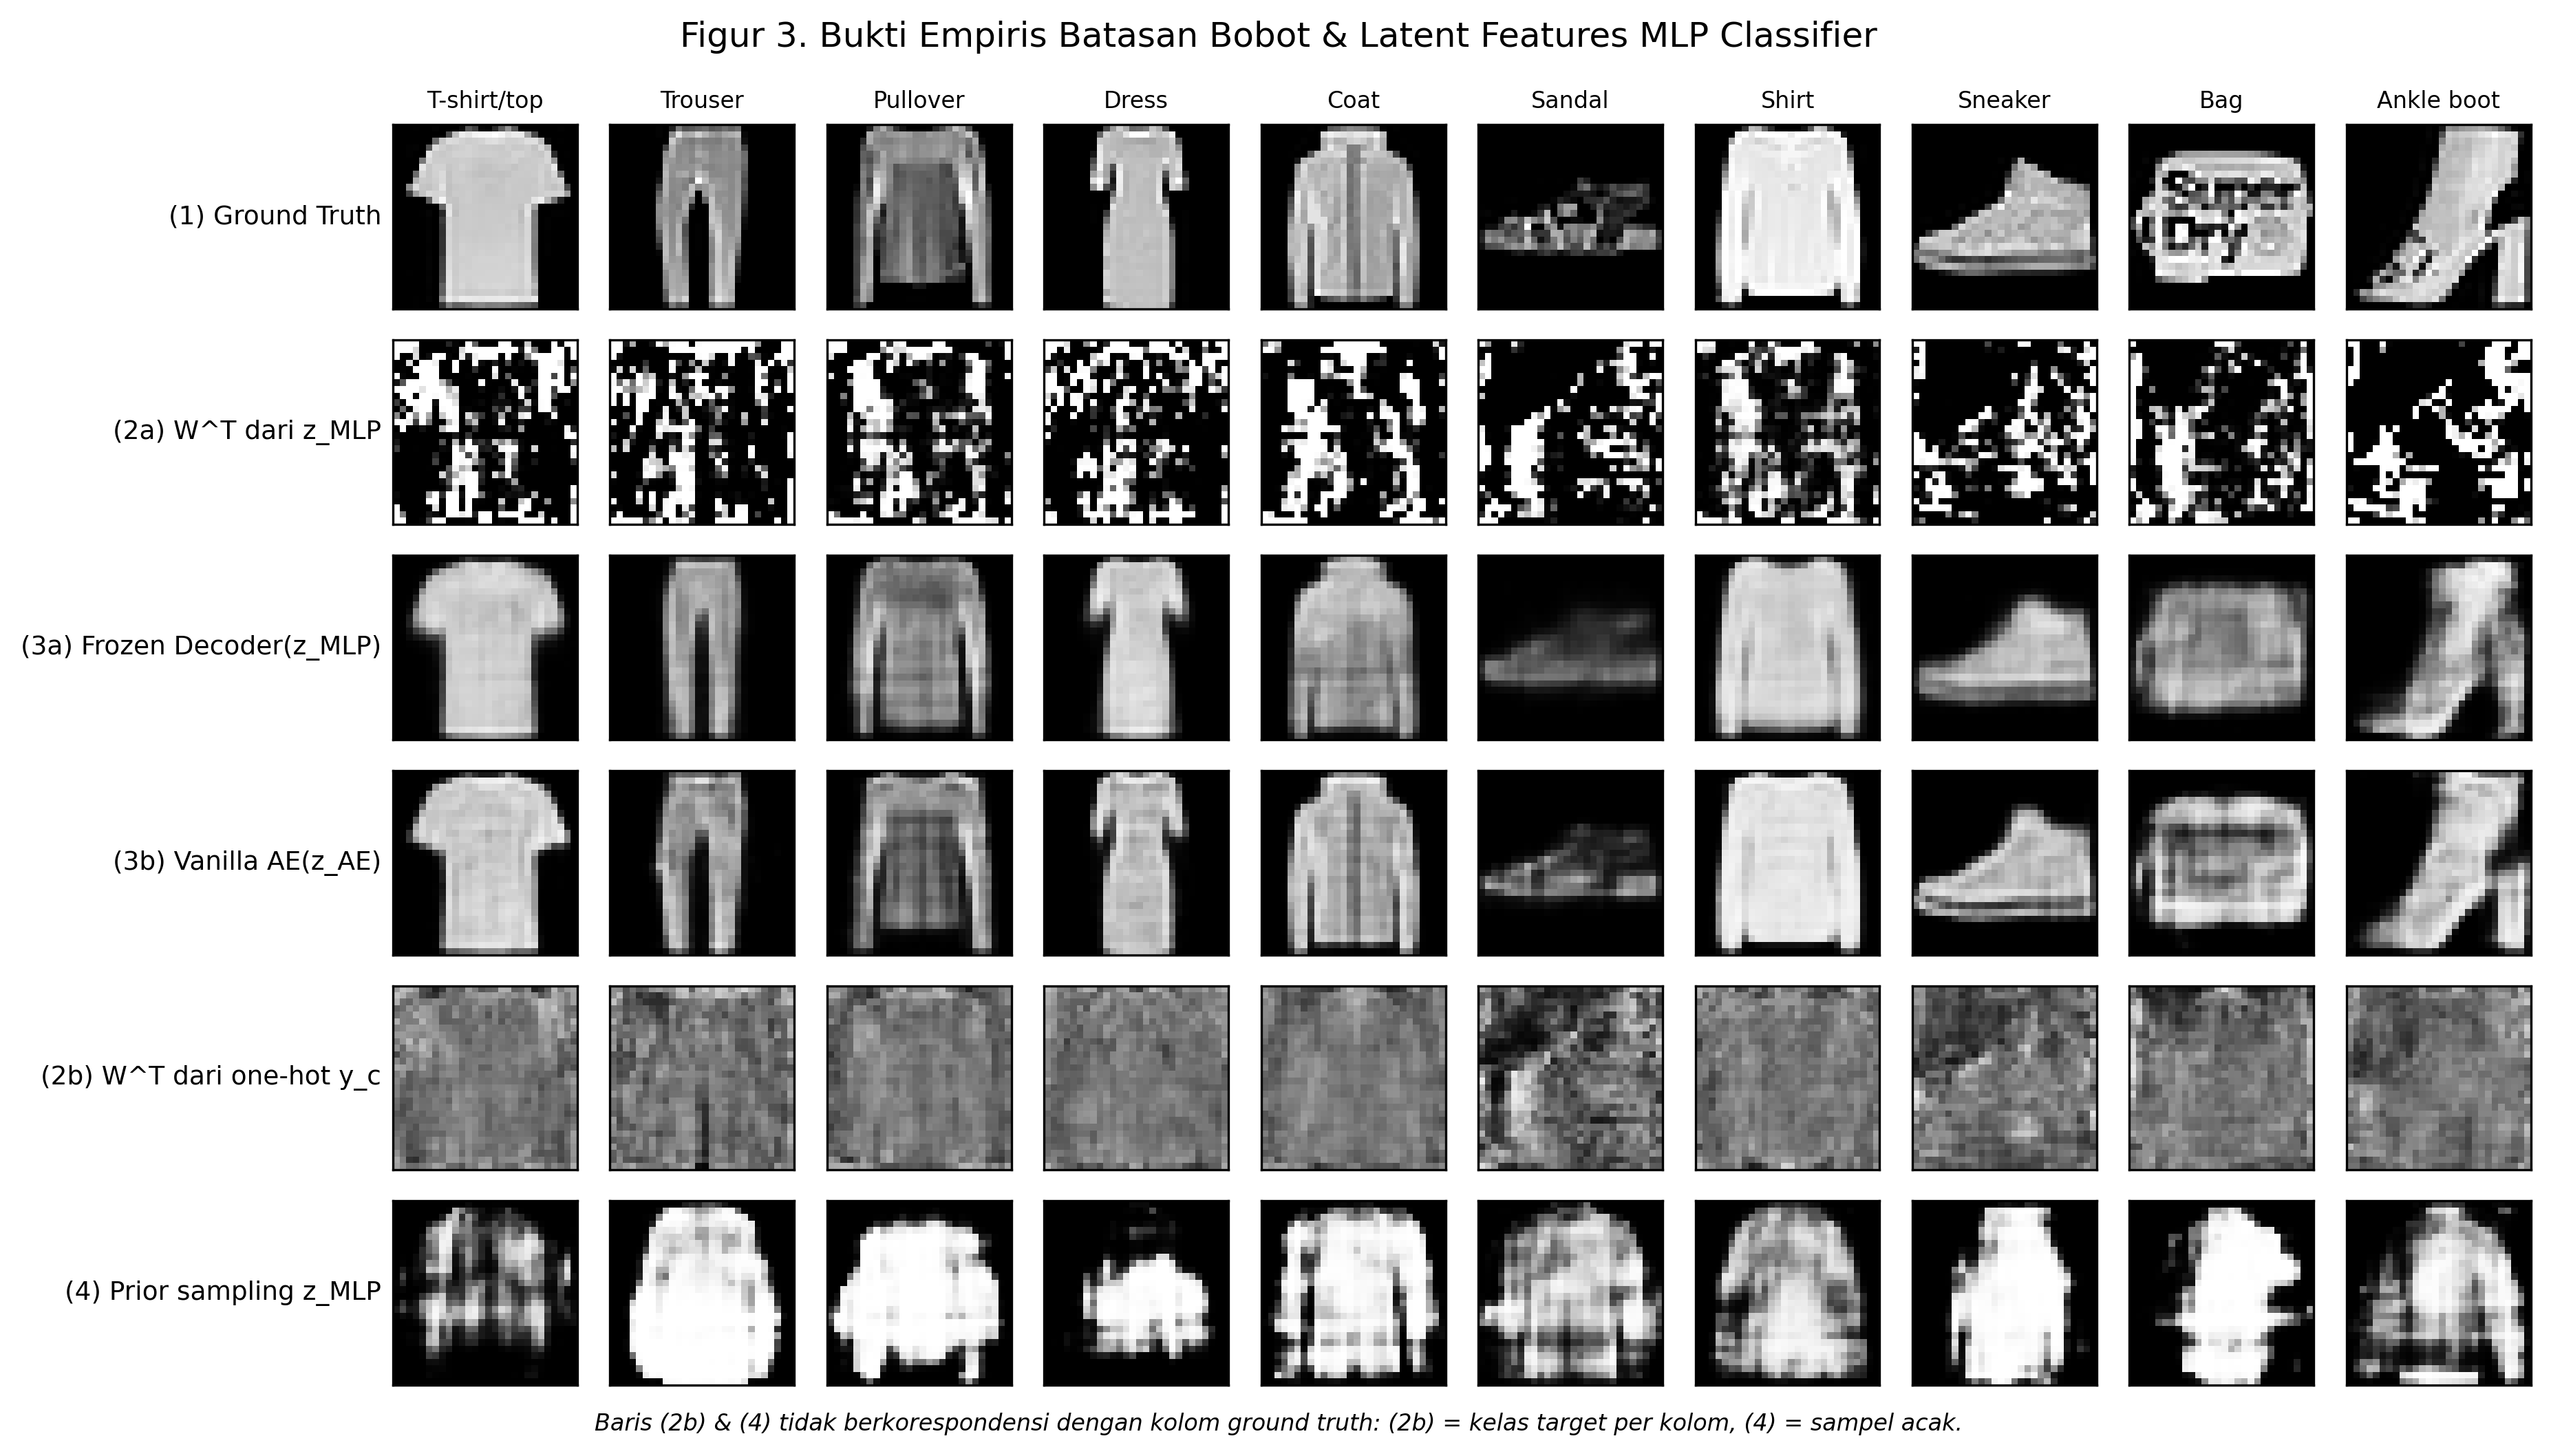

In [28]:
figure3_mlp_limitations(mlp_tensors, cfg)
show_fig("fig3_mlp_limitations.png")